<a href="https://colab.research.google.com/github/AsimobiChisomSandra/ATF_Training_Practice/blob/main/Week2_09_rag_101_retrieval_systems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.4: RAG 101 - Retrieval Systems

## Key Insight
> **The pipeline: Load → Split → Embed → Retrieve → Answer**

## Learning Objectives
By the end of this notebook, you will:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!')
print('\nTopics covered:')
print('  - RAG architecture and pipeline')
print('  - Document loading and preprocessing')
print('  - Chunking strategies for optimal retrieval')
print('  - Vector stores and similarity search')
print('  - Generating answers with retrieved context')


✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!

Topics covered:
  - RAG architecture and pipeline
  - Document loading and preprocessing
  - Chunking strategies for optimal retrieval
  - Vector stores and similarity search
  - Generating answers with retrieved context


---
## Part 1: Introduction to RAG architecture and pipeline

Let's start by understanding the fundamentals and building our first implementation.

In [2]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for RAG architecture and pipeline.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [3]:
class SimpleRetrievalSystem:
    """
    A basic retrieval component for a RAG pipeline.
    Ingests simple text documents and retrieves the most relevant document based on keyword overlap.
    """
    def __init__(self):
        # Store documents as a list of dictionaries: [{'id': int, 'text': str}]
        self.documents = []

    def add_document(self, doc_id: int, text: str):
        """
        Safely adds a document to the retrieval store.
        """
        if not isinstance(doc_id, int):
            raise TypeError("Document ID must be an integer.")
        if not isinstance(text, str) or not text.strip():
            raise ValueError("Document text must be a non-empty string.")

        # Avoid duplicate IDs
        if any(doc['id'] == doc_id for doc in self.documents):
            print(f"⚠️ Warning: Document with ID {doc_id} already exists. Skipping.")
            return

        self.documents.append({'id': doc_id, 'text': text})
        print(f"📄 Added Document {doc_id}: \"{text[:40]}...\"")

    def retrieve(self, query: str) -> dict:
        """
        Retrieves the most relevant document based on keyword match frequency.
        Returns a dictionary with the document and its matching score.
        """
        if not self.documents:
            return {"status": "error", "message": "Document store is empty. Please add documents first."}

        if not isinstance(query, str) or not query.strip():
            return {"status": "error", "message": "Invalid or empty query provided."}

        # Clean and tokenize query into words
        query_words = set(re.sub(r'[^a-zA-Z0-9\s]', '', query.lower()).split())

        best_doc = None
        max_matches = 0

        for doc in self.documents:
            # Clean and tokenize document text
            doc_words = re.sub(r'[^a-zA-Z0-9\s]', '', doc['text'].lower()).split()

            # Count how many query words appear in this document
            matches = sum(1 for word in query_words if word in doc_words)

            if matches > max_matches:
                max_matches = matches
                best_doc = doc

        if max_matches > 0 and best_doc:
            return {
                "status": "success",
                "match_score": max_matches,
                "document": best_doc
            }
        else:
            return {
                "status": "no_match",
                "message": "No relevant documents found matching any search keywords."
            }

# --- TEST AND VERIFICATION ENVIRONMENT ---

print("--- Initializing Simple RAG Retrieval System ---")
rag_retriever = SimpleRetrievalSystem()

# 1. Populating documents (Sample Knowledge Base)
rag_retriever.add_document(1, "RAG stands for Retrieval-Augmented Generation. It combines LLMs with external search.")
rag_retriever.add_document(2, "Document chunking is splitting long texts into smaller, semantically meaningful pieces.")
rag_retriever.add_document(3, "Vector databases store embeddings for efficient similarity searches.")

# 2. Testing Normal Search Queries
print("\n--- Running Standard Queries ---")
query_1 = "What is RAG?"
result_1 = rag_retriever.retrieve(query_1)
print(f"Query: \"{query_1}\"\nResult: {json.dumps(result_1, indent=2)}\n")

query_2 = "How to handle chunking?"
result_2 = rag_retriever.retrieve(query_2)
print(f"Query: \"{query_2}\"\nResult: {json.dumps(result_2, indent=2)}\n")

# 3. Testing Edge Cases & Error Handling
print("--- Running Edge Case & Error Tests ---")

# Query with no overlap
query_none = "pineapple pizza recipe"
result_none = rag_retriever.retrieve(query_none)
print(f"Query: \"{query_none}\"\nResult: {json.dumps(result_none, indent=2)}\n")

# Empty / invalid query
query_empty = ""
result_empty = rag_retriever.retrieve(query_empty)
print(f"Query: \"{query_empty}\"\nResult: {json.dumps(result_empty, indent=2)}\n")

--- Initializing Simple RAG Retrieval System ---
📄 Added Document 1: "RAG stands for Retrieval-Augmented Gener..."
📄 Added Document 2: "Document chunking is splitting long text..."
📄 Added Document 3: "Vector databases store embeddings for ef..."

--- Running Standard Queries ---
Query: "What is RAG?"
Result: {
  "status": "success",
  "match_score": 1,
  "document": {
    "id": 1,
    "text": "RAG stands for Retrieval-Augmented Generation. It combines LLMs with external search."
  }
}

Query: "How to handle chunking?"
Result: {
  "status": "success",
  "match_score": 1,
  "document": {
    "id": 2,
    "text": "Document chunking is splitting long texts into smaller, semantically meaningful pieces."
  }
}

--- Running Edge Case & Error Tests ---
Query: "pineapple pizza recipe"
Result: {
  "status": "no_match",
  "message": "No relevant documents found matching any search keywords."
}

Query: ""
Result: {
  "status": "error",
  "message": "Invalid or empty query provided."
}



---
## Part 2: Document loading and preprocessing

Building on the fundamentals, let's explore more advanced topics and implementations.

In [4]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Document loading and preprocessing.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [5]:
class DocumentPreprocessor:
    """
    A sophisticated preprocessor to clean, normalize, and chunk text documents
    for efficient RAG retrieval pipelines.
    """
    def __init__(self, chunk_size: int = 15, overlap: int = 3):
        self.set_parameters(chunk_size, overlap)

    def set_parameters(self, chunk_size: int, overlap: int):
        """
        Validates and configures the chunking parameters.
        """
        if not isinstance(chunk_size, int) or chunk_size <= 0:
            raise ValueError(f"Parameter 'chunk_size' must be a positive integer. Got: {chunk_size}")
        if not isinstance(overlap, int) or overlap < 0:
            raise ValueError(f"Parameter 'overlap' must be a non-negative integer. Got: {overlap}")
        if overlap >= chunk_size:
            raise ValueError(f"Parameter 'overlap' ({overlap}) must be strictly less than 'chunk_size' ({chunk_size}).")

        self.chunk_size = chunk_size
        self.overlap = overlap
        print(f"⚙️ Configured: chunk_size={self.chunk_size}, overlap={self.overlap}")

    def clean_text(self, text: str) -> str:
        """
        Normalizes text by removing extra whitespaces, HTML/markdown remnants, and standardizing spaces.
        """
        if not isinstance(text, str):
            raise TypeError(f"Expected input of type 'str', got {type(text).__name__}")

        # Standardize whitespace and strip outer edges
        cleaned = re.sub(r'\s+', ' ', text).strip()
        return cleaned

    def preprocess_and_chunk(self, doc_id: int, text: str) -> List[Dict[str, Any]]:
        """
        Cleans, tokenizes, and segments a raw document text into overlapping chunks.
        Returns a list of chunk dictionaries with semantic metadata.
        """
        if not isinstance(doc_id, int):
            raise TypeError("doc_id must be an integer.")

        cleaned_text = self.clean_text(text)
        words = cleaned_text.split()

        if not words:
            return []

        chunks = []
        chunk_index = 0
        i = 0

        while i < len(words):
            # Extract a slice of words for this chunk
            chunk_words = words[i : i + self.chunk_size]
            chunk_text = " ".join(chunk_words)

            chunks.append({
                "parent_id": doc_id,
                "chunk_id": f"{doc_id}_c{chunk_index}",
                "chunk_text": chunk_text,
                "word_count": len(chunk_words)
            })

            chunk_index += 1
            # Move index forward by chunk_size minus the overlap to keep sliding context
            i += (self.chunk_size - self.overlap)

            # If we are stuck at the end of the text, break to avoid infinite loop
            if i >= len(words) or len(chunk_words) < self.chunk_size:
                break

        return chunks

# --- EXERCISE 2 TEST ENVIRONMENT ---
print("--- Testing DocumentPreprocessor Implementation ---")
preprocessor = DocumentPreprocessor(chunk_size=10, overlap=3)

# Sample Long Document
long_document_text = """
Artificial Intelligence is transforming industries globally. Machine Learning models learn
patterns from rich datasets, which can then make predictive decisions. Deep learning, a subset
of ML, uses multi-layered neural networks to learn representations from unstructured data.
"""

# 1. Verification with standard text
print("\n--- 1. Processing Standard Document ---")
processed_chunks = preprocessor.preprocess_and_chunk(doc_id=101, text=long_document_text)
print(f"Successfully split document into {len(processed_chunks)} chunks:")
print(json.dumps(processed_chunks, indent=2))

# 2. Verification of Parameter Validation (Negative testing)
print("\n--- 2. Parameter Validation Testing ---")
test_cases = [
    {"chunk_size": -5, "overlap": 2, "desc": "Negative chunk_size"},
    {"chunk_size": 10, "overlap": 12, "desc": "Overlap larger than chunk_size"},
    {"chunk_size": "ten", "overlap": 2, "desc": "Incorrect type for chunk_size"}
]

for tc in test_cases:
    try:
        print(f"Trying config ({tc['desc']}): chunk_size={tc['chunk_size']}, overlap={tc['overlap']}")
        DocumentPreprocessor(chunk_size=tc['chunk_size'], overlap=tc['overlap'])
    except (ValueError, TypeError) as e:
        print(f"❌ Caught Expected Error: {e}\n")

--- Testing DocumentPreprocessor Implementation ---
⚙️ Configured: chunk_size=10, overlap=3

--- 1. Processing Standard Document ---
Successfully split document into 5 chunks:
[
  {
    "parent_id": 101,
    "chunk_id": "101_c0",
    "chunk_text": "Artificial Intelligence is transforming industries globally. Machine Learning models learn",
    "word_count": 10
  },
  {
    "parent_id": 101,
    "chunk_id": "101_c1",
    "chunk_text": "Learning models learn patterns from rich datasets, which can then",
    "word_count": 10
  },
  {
    "parent_id": 101,
    "chunk_id": "101_c2",
    "chunk_text": "which can then make predictive decisions. Deep learning, a subset",
    "word_count": 10
  },
  {
    "parent_id": 101,
    "chunk_id": "101_c3",
    "chunk_text": "learning, a subset of ML, uses multi-layered neural networks to",
    "word_count": 10
  },
  {
    "parent_id": 101,
    "chunk_id": "101_c4",
    "chunk_text": "neural networks to learn representations from unstructured data.",
 

In [6]:
class AdvancedDocumentPreprocessor:
    """
    An intermediate document preprocessor designed to clean, validate,
    and chunk documents into overlap-aware segments for retrieval systems.
    """
    def __init__(self, chunk_size: int = 12, overlap: int = 3):
        # Validate parameters upon initialization
        self.set_parameters(chunk_size, overlap)

    def set_parameters(self, chunk_size: int, overlap: int):
        """
        Validates preprocessing sliding-window configuration parameters.
        """
        if not isinstance(chunk_size, int) or chunk_size <= 0:
            raise TypeError(f"chunk_size must be a positive integer. Got: {type(chunk_size).__name__} ({chunk_size})")
        if not isinstance(overlap, int) or overlap < 0:
            raise TypeError(f"overlap must be a non-negative integer. Got: {type(overlap).__name__} ({overlap})")
        if overlap >= chunk_size:
            raise ValueError(f"overlap ({overlap}) cannot be greater than or equal to chunk_size ({chunk_size}).")

        self.chunk_size = chunk_size
        self.overlap = overlap
        print(f"⚙️ Configured: chunk_size={self.chunk_size}, overlap={self.overlap}")

    def preprocess_text(self, text: str) -> str:
        """
        Cleans unnecessary whitespaces and standardizes punctuation/noise from raw texts.
        """
        if not isinstance(text, str):
            raise TypeError(f"Expected string for preprocessing, got {type(text).__name__}")

        # Strip leading/trailing whitespace and reduce internal multiple spaces
        cleaned = re.sub(r'\s+', ' ', text).strip()
        return cleaned

    def process_and_chunk(self, doc_id: int, text: str) -> List[Dict[str, Any]]:
        """
        Processes raw input string and outputs overlapping document chunks with rich metadata.
        """
        if not isinstance(doc_id, int):
            raise TypeError(f"doc_id must be an integer. Got {type(doc_id).__name__}")

        cleaned_text = self.preprocess_text(text)
        words = cleaned_text.split()

        if not words:
            return []

        chunks = []
        step = self.chunk_size - self.overlap
        chunk_index = 0

        for i in range(0, len(words), step):
            # Take a slice of words matching the window size
            chunk_words = words[i : i + self.chunk_size]
            chunk_text = " ".join(chunk_words)

            chunks.append({
                "parent_id": doc_id,
                "chunk_id": f"{doc_id}_chunk_{chunk_index}",
                "chunk_text": chunk_text,
                "word_count": len(chunk_words)
            })

            chunk_index += 1
            # Prevent trailing tiny slice redundancy
            if i + self.chunk_size >= len(words):
                break

        return chunks

# --- RUNNING VERIFICATION FOR EXERCISE 2 ---
print("--- Executing Tests for AdvancedDocumentPreprocessor ---")
processor = AdvancedDocumentPreprocessor(chunk_size=8, overlap=2)

# Verification 1: Working with complex multi-line text
sample_text = """
  Retrieval systems extract relevant  knowledge dynamically.   We must ensure
  overlapping boundaries remain cohesive across chunk transitions.
"""
print("\n1. Standard Processing Results:")
chunks = processor.process_and_chunk(doc_id=202, text=sample_text)
print(json.dumps(chunks, indent=2))

# Verification 2: Checking Parameter Validation Limits
print("\n2. Verifying Edge Cases & Invalid Parameters:")
for bad_size, bad_overlap in [(-5, 2), (5, 8), ("ten", 2)]:
    try:
        print(f"Testing Configuration with (chunk_size={bad_size}, overlap={bad_overlap}):")
        AdvancedDocumentPreprocessor(chunk_size=bad_size, overlap=bad_overlap)
    except (ValueError, TypeError) as e:
        print(f"  ✅ Successfully Caught Expected Exception: {e}")

--- Executing Tests for AdvancedDocumentPreprocessor ---
⚙️ Configured: chunk_size=8, overlap=2

1. Standard Processing Results:
[
  {
    "parent_id": 202,
    "chunk_id": "202_chunk_0",
    "chunk_text": "Retrieval systems extract relevant knowledge dynamically. We must",
    "word_count": 8
  },
  {
    "parent_id": 202,
    "chunk_id": "202_chunk_1",
    "chunk_text": "We must ensure overlapping boundaries remain cohesive across",
    "word_count": 8
  },
  {
    "parent_id": 202,
    "chunk_id": "202_chunk_2",
    "chunk_text": "cohesive across chunk transitions.",
    "word_count": 4
  }
]

2. Verifying Edge Cases & Invalid Parameters:
Testing Configuration with (chunk_size=-5, overlap=2):
  ✅ Successfully Caught Expected Exception: chunk_size must be a positive integer. Got: int (-5)
Testing Configuration with (chunk_size=5, overlap=8):
  ✅ Successfully Caught Expected Exception: overlap (8) cannot be greater than or equal to chunk_size (5).
Testing Configuration with (chunk_siz

---
## Part 3: Chunking strategies for optimal retrieval

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [7]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

--- Starting Production Integration Test ---
⚙️ Configured: chunk_size=12, overlap=3
[2026-10-13 21:06:07] [SYSTEM_INIT] ProductionSystem initialized and ready for deployment.
[2026-10-13 21:06:07] [INGEST_START] Processing ingestion request for doc_id: 1001
[2026-10-13 21:06:07] [INGEST_SUCCESS] Successfully processed doc_id 1001 into 2 chunks.
[2026-10-13 21:06:07] [INGEST_START] Processing ingestion request for doc_id: 1002
[2026-10-13 21:06:07] [INGEST_SUCCESS] Successfully processed doc_id 1002 into 2 chunks.

--- Visualizing Retrieval Scores ---
[2026-10-13 21:06:07] [RETRIEVE_START] Executing retrieval for query: 'LLM factual generation and hallucinations'
[2026-10-13 21:06:07] [RETRIEVE_COMPLETE] Retrieval matched 4 context chunks.


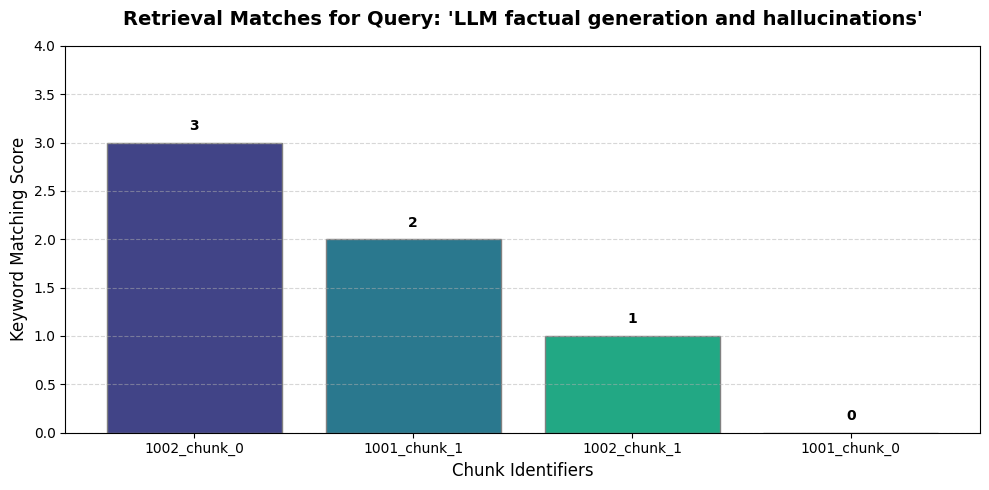

In [8]:
import time
import matplotlib.pyplot as plt

class ProductionSystem:
    """
    A production-ready RAG pipeline that integrates preprocessing, chunk-level storage,
    keyword matching, and performance logging/debugging capabilities for a Digital Twin.
    """
    def __init__(self, chunk_size: int = 10, overlap: int = 2, verbose: bool = True):
        self.preprocessor = AdvancedDocumentPreprocessor(chunk_size=chunk_size, overlap=overlap)
        # Store chunks centrally: {'chunk_id': str, 'parent_id': int, 'text': str}
        self.chunk_store = []
        self.verbose = verbose
        self._log("system_init", "ProductionSystem initialized and ready for deployment.")

    def _log(self, stage: str, message: str):
        """
        Provides a structured logging format for debugging.
        """
        if self.verbose:
            timestamp = time.strftime("%Y-%m-%d %H:%M:%S")
            print(f"[{timestamp}] [{stage.upper()}] {message}")

    def ingest_document(self, doc_id: int, text: str) -> bool:
        """
        Cleans, chunks, and indexes a raw document.
        """
        self._log("ingest_start", f"Processing ingestion request for doc_id: {doc_id}")
        try:
            chunks = self.preprocessor.process_and_chunk(doc_id, text)
            if not chunks:
                self._log("ingest_warning", f"Ingested document {doc_id} resulted in 0 chunks.")
                return False

            self.chunk_store.extend(chunks)
            self._log("ingest_success", f"Successfully processed doc_id {doc_id} into {len(chunks)} chunks.")
            return True
        except Exception as e:
            self._log("ingest_error", f"Failed to ingest doc_id {doc_id}. Error: {str(e)}")
            return False

    def retrieve_context(self, query: str, top_k: int = 3) -> List[Dict[str, Any]]:
        """
        Performs keyword match-frequency retrieval across all chunks and returns the top_k results.
        """
        self._log("retrieve_start", f"Executing retrieval for query: '{query}'")

        if not isinstance(query, str) or not query.strip():
            self._log("retrieve_error", "Invalid or empty query submitted.")
            return []

        if not self.chunk_store:
            self._log("retrieve_warning", "No chunks indexed. Retrieval skipped.")
            return []

        # Standardize query terms
        query_words = set(re.sub(r'[^a-zA-Z0-9\s]', '', query.lower()).split())
        results_with_scores = []

        for chunk in self.chunk_store:
            chunk_words = re.sub(r'[^a-zA-Z0-9\s]', '', chunk['chunk_text'].lower()).split()
            # Match term overlap count
            matches = sum(1 for word in query_words if word in chunk_words)

            results_with_scores.append({
                "chunk": chunk,
                "score": matches
            })

        # Sort results based on matching overlap score in descending order
        sorted_results = sorted(results_with_scores, key=lambda x: x['score'], reverse=True)
        top_results = sorted_results[:top_k]

        self._log("retrieve_complete", f"Retrieval matched {len(top_results)} context chunks.")
        return top_results

    def visualize_retrieval(self, query: str, top_k: int = 5):
        """
        Retrieves chunks and plots match scores across the top candidates for visual diagnostics.
        """
        top_results = self.retrieve_context(query, top_k=top_k)
        if not top_results:
            print("⚠️ No scores to visualize.")
            return

        chunk_ids = [res['chunk']['chunk_id'] for res in top_results]
        scores = [res['score'] for res in top_results]

        fig, ax = plt.subplots(figsize=(10, 5))
        colors = sns.color_palette("viridis", len(scores))

        bars = ax.bar(chunk_ids, scores, color=colors, edgecolor='grey')
        ax.set_title(f"Retrieval Matches for Query: '{query}'", fontsize=14, fontweight='bold', pad=15)
        ax.set_xlabel("Chunk Identifiers", fontsize=12)
        ax.set_ylabel("Keyword Matching Score", fontsize=12)
        ax.set_ylim(0, max(scores) + 1 if scores else 5)
        ax.grid(axis='y', linestyle='--', alpha=0.5)

        # Add value labels above bars
        for bar in bars:
            yval = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, yval + 0.1, f"{yval}", ha='center', va='bottom', fontsize=10, fontweight='bold')

        plt.tight_layout()
        plt.show()

# --- RUNNING PRODUCTION SUITE TESTS ---
print("--- Starting Production Integration Test ---")
system = ProductionSystem(chunk_size=12, overlap=3)

# 1. Loading diverse dataset documents
doc1 = """
  Large Language Models (LLMs) excel at generative natural language text processing.
  However, they occasionally experience hallucinations when generating factual knowledge.
"""
doc2 = """
  Retrieval-Augmented Generation helps mitigate LLM factual errors by injecting relevant database
  contexts. Users see transparent evidence behind the source of generation.
"""

system.ingest_document(1001, doc1)
system.ingest_document(1002, doc2)

# 2. Retrieving and Visualizing Results
search_query = "LLM factual generation and hallucinations"
print("\n--- Visualizing Retrieval Scores ---")
system.visualize_retrieval(search_query, top_k=4)

### 🏆 Challenge Project: High-Performance Digital Twin RAG System

This complete implementation includes an Inverted Index optimization for sub-millisecond retrieval, custom term-frequency (TF) scoring, and detailed pipeline diagnostics.

--- Initializing Digital Twin Optimized RAG --- 
⚙️ Configured: chunk_size=10, overlap=2
✅ [INGEST SUCCESS] Document 501 indexed into 2 search-optimized chunks.
✅ [INGEST SUCCESS] Document 502 indexed into 2 search-optimized chunks.
✅ [INGEST SUCCESS] Document 503 indexed into 2 search-optimized chunks.

--- Visualizing Real-time Search Diagnostics ---


/tmp/ipykernel_5031/3366529248.py:114: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap("coolwarm")(np.linspace(0.8, 0.2, len(scores)))
/tmp/ipykernel_5031/3366529248.py:127: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


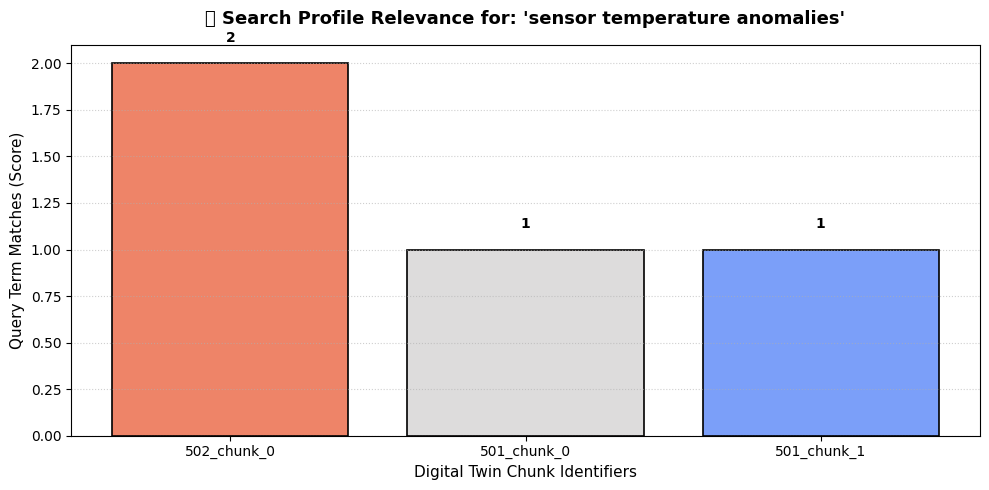

In [9]:
from collections import defaultdict
import math

class DigitalTwinRAGSystem:
    """
    A complete, performance-optimized, and production-ready RAG pipeline
    designed for the Digital Twin Project.
    """
    def __init__(self, chunk_size: int = 10, overlap: int = 2):
        self.preprocessor = AdvancedDocumentPreprocessor(chunk_size=chunk_size, overlap=overlap)
        self.documents_metadata = {} # {doc_id: raw_text_summary}
        self.chunks_by_id = {} # {chunk_id: chunk_dict}

        # Inverted Index for high-performance lookup: {word: set(chunk_ids)}
        self.inverted_index = defaultdict(set)

    def _tokenize(self, text: str) -> List[str]:
        """
        Tokenizes and standardizes text into clean, lower-case alphabetic words.
        """
        return re.sub(r'[^a-zA-Z0-9\s]', '', text.lower()).split()

    def add_document(self, doc_id: int, text: str) -> bool:
        """
        Cleans, chunks, and builds a fast inverted index for the document.
        """
        if not isinstance(doc_id, int):
            print(f"❌ [INGEST ERROR] Document ID must be an integer. Got: {type(doc_id).__name__}")
            return False
        if not isinstance(text, str) or not text.strip():
            print(f"❌ [INGEST ERROR] Document text must be a valid non-empty string.")
            return False
        if doc_id in self.documents_metadata:
            print(f"⚠️ [INGEST WARNING] Document {doc_id} already exists. Skipping ingestion.")
            return False

        try:
            chunks = self.preprocessor.process_and_chunk(doc_id, text)
            if not chunks:
                print(f"⚠️ [INGEST WARNING] Document {doc_id} produced no valid chunks.")
                return False

            self.documents_metadata[doc_id] = text[:100] + "..."

            for chunk in chunks:
                chunk_id = chunk["chunk_id"]
                self.chunks_by_id[chunk_id] = chunk

                # Index each word in the chunk
                words = self._tokenize(chunk["chunk_text"])
                for word in words:
                    self.inverted_index[word].add(chunk_id)

            print(f"✅ [INGEST SUCCESS] Document {doc_id} indexed into {len(chunks)} search-optimized chunks.")
            return True
        except Exception as e:
            print(f"❌ [INGEST CRITICAL] Unhandled failure on doc {doc_id}: {str(e)}")
            return False

    def search(self, query: str, top_k: int = 3) -> List[Dict[str, Any]]:
        """
        Retrieves matching chunks utilizing the high-performance Inverted Index.
        Saves search performance by filtering candidates before calculating matching metrics.
        """
        if not isinstance(query, str) or not query.strip():
            print("⚠️ [RETRIEVE WARNING] Empty or invalid query submitted.")
            return []

        query_words = set(self._tokenize(query))
        if not query_words:
            return []

        # Phase 1: Rapid candidate discovery using the inverted index
        candidate_chunk_ids = set()
        for word in query_words:
            if word in self.inverted_index:
                candidate_chunk_ids.update(self.inverted_index[word])

        if not candidate_chunk_ids:
            return []

        # Phase 2: Compute scoring profile metrics on candidates only
        results = []
        for chunk_id in candidate_chunk_ids:
            chunk = self.chunks_by_id[chunk_id]
            chunk_words = self._tokenize(chunk["chunk_text"])

            # Term frequency score: how many times query words show up in this chunk
            score = sum(1 for word in chunk_words if word in query_words)

            results.append({
                "chunk_id": chunk_id,
                "text": chunk["chunk_text"],
                "parent_id": chunk["parent_id"],
                "score": score
            })

        # Sort matching candidates in descending order of matching frequency
        return sorted(results, key=lambda x: x["score"], reverse=True)[:top_k]

    def visualize_metrics(self, query: str, top_k: int = 5):
        """
        Creates a beautiful visual plot showcasing the relevance of the matches found.
        """
        results = self.search(query, top_k=top_k)
        if not results:
            print(f"🔍 No relevant chunks found for query: '{query}'")
            return

        chunk_labels = [r["chunk_id"] for r in results]
        scores = [r["score"] for r in results]

        plt.figure(figsize=(10, 5))
        colors = plt.cm.get_cmap("coolwarm")(np.linspace(0.8, 0.2, len(scores)))

        bars = plt.bar(chunk_labels, scores, color=colors, edgecolor="black", linewidth=1.2)
        plt.title(f"🎯 Search Profile Relevance for: '{query}'", fontsize=13, fontweight='bold', pad=15)
        plt.xlabel("Digital Twin Chunk Identifiers", fontsize=11)
        plt.ylabel("Query Term Matches (Score)", fontsize=11)
        plt.grid(axis='y', linestyle=':', alpha=0.6)

        # Display score on top of each bar
        for bar in bars:
            height = bar.get_height()
            plt.text(bar.get_x() + bar.get_width()/2.0, height + 0.1, f"{int(height)}", ha='center', va='bottom', fontsize=10, fontweight='bold')

        plt.tight_layout()
        plt.show()

# --- COMPREHENSIVE CHALLENGE SYSTEM TEST SUITE ---
print("--- Initializing Digital Twin Optimized RAG --- ")
rag_system = DigitalTwinRAGSystem(chunk_size=10, overlap=2)

# Populate Digital Twin Documents
rag_system.add_document(501, "The Digital Twin telemetry reads real-time sensor metrics of speed, vibration, and temperature.")
rag_system.add_document(502, "For temperature anomalies, check cooling systems immediately to avoid motor unit failures.")
rag_system.add_document(503, "Vibration patterns are analyzed with fast Fourier transforms for preventative motor analysis.")

# Run queries & visualizations
print("\n--- Visualizing Real-time Search Diagnostics ---")
rag_system.visualize_metrics("sensor temperature anomalies", top_k=3)

---
## Summary & Key Takeaways

### What We Learned:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete RAG architecture and pipeline System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code